# Analisis Pendapatan Transaksi POS per tahun 2024 dan 2025
Tujuan Analasis: Menghitung total pendapatan per tahun dari data transaksi POS.

**Langkah Kerjanya:**
1. Membaca dataset CSV menggunakan Pandas.
2. Memeriksa apakah terdapat missing value dan menanganinya.
3. Membersihkan data agar bisa diolah.
4. Menghitung total pendapatan tahun 2024 dan 2025.
5. Menyimpan hasil pengerjaan dan mengunggahnya ke GitHub.

## 1.  Import Library dan Membaca File CSV

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# dtype=str: semua kolom dibaca sebagai teks dulu,
# supaya "13.000" dan "7500,00" tidak salah tebak oleh pandas
df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv", dtype=str)
print("Jumlah baris:", len(df))
df.head()

Jumlah baris: 5030


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


## 2. Memeriksa informasi dataset
Karena sebelum mengolah data, kita harus mengetahui jenis data yang tersedia. Misalnya, tanggal seharusnya bertipe datetime, sedangkan harga seharusnya bertipe numerik.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_transaksi   5030 non-null   str  
 1   tanggal        5030 non-null   str  
 2   kode_gerai     5030 non-null   str  
 3   kode_kasir     4769 non-null   str  
 4   kode_produk    5030 non-null   str  
 5   jumlah         5030 non-null   str  
 6   harga_satuan   5030 non-null   str  
 7   diskon_persen  5030 non-null   str  
 8   status         5030 non-null   str  
dtypes: str(9)
memory usage: 589.1 KB


## 3. Memeriksa Masalah Data
Sebelum mengubah apa pun, kita periksa dulu kondisi datanya: missing value, duplikat, isi kolom `status` dan `diskon_persen`, serta pola format tanggal dan harga.

In [6]:
print("Missing value per kolom:")
print(df.isna().sum())

Missing value per kolom:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


Hasil pemeriksaan dataset: Ternyata hanya kode_kasir yang memiliki missing value.

In [7]:
print("Baris duplikat:", df.duplicated().sum())
print("")
print("Status:")
print(df["status"].value_counts())
print("")
print("Diskon (%):")
print(df["diskon_persen"].value_counts())

Baris duplikat: 30

Status:
status
SELESAI    4749
BATAL       191
RETUR        90
Name: count, dtype: int64

Diskon (%):
diskon_persen
0     3848
10     420
5      346
15     271
20     145
Name: count, dtype: int64


In [8]:
# Mengubah semua angka jadi 9 untuk melihat pola formatnya
print(df["tanggal"].str.replace(r"\d", "9", regex=True).value_counts())
print("")
print(df["harga_satuan"].str.replace(r"\d", "9", regex=True).value_counts())

tanggal
9999-99-99    4839
99-99-9999     105
99/99/9999      86
Name: count, dtype: int64

harga_satuan
99999       3974
9999         960
99999,99      40
99.999        38
9999,99       11
9.999          7
Name: count, dtype: int64


## 4. Menangani missing value dan duplikat

In [9]:
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK_DIKETAHUI")

print("Missing value setelah diperbaiki:")
print(df.isnull().sum())

Missing value setelah diperbaiki:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64


In [10]:
print("Data sebelum duplikat dihapus:", len(df))
print("Jumlah data duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Data setelah duplikat dihapus:", len(df))

Data sebelum duplikat dihapus: 5030
Jumlah data duplikat: 30
Data setelah duplikat dihapus: 5000


## 5. Seragamkan tanggal dan buat kolom tahun

In [11]:
def ubah_tanggal(teks):
    teks = teks.strip()
    if teks[4] == "-":                    # 2025-06-02 (tahun di depan)
        return pd.to_datetime(teks, format="%Y-%m-%d")
    teks = teks.replace("/", "-")         # 26/03/2025 menjadi 26-03-2025
    return pd.to_datetime(teks, format="%d-%m-%Y")

df["tanggal"] = df["tanggal"].apply(ubah_tanggal)
df["tahun"] = df["tanggal"].dt.year
print(df["tahun"].value_counts().sort_index())

tahun
2024    2492
2025    2508
Name: count, dtype: int64


## 6. Seragamkan harga dan tipe angka

In [12]:
def ubah_harga(teks):
    teks = teks.strip()
    teks = teks.split(",")[0]       # "7500,00" -> "7500"
    teks = teks.replace(".", "")    # "13.000"  -> "13000"
    return int(teks)

df["harga_satuan"] = df["harga_satuan"].apply(ubah_harga)
df["jumlah"] = df["jumlah"].astype(int)
df["diskon_persen"] = df["diskon_persen"].astype(int)

df[["jumlah", "harga_satuan", "diskon_persen"]].describe()

,jumlah,harga_satuan,diskon_persen
count,5000.000000,5000.00000,5000.000000
mean,5.611600,22168.10000,2.567000
std,68.993988,15199.09849,5.212576
min,-12.000000,4000.00000,0.000000
25%,1.000000,11000.00000,0.000000
50%,2.000000,16000.00000,0.000000
75%,3.000000,32000.00000,0.000000
max,2375.000000,54000.00000,20.000000


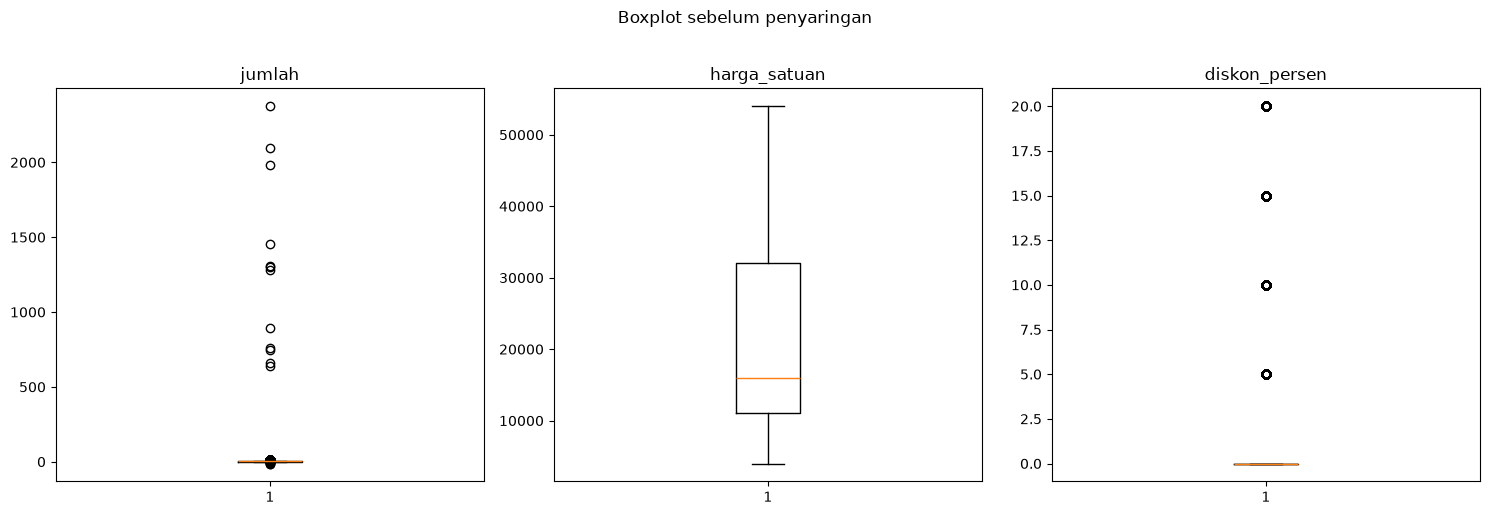

In [13]:
fitur = ["jumlah", "harga_satuan", "diskon_persen"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kolom in zip(axes, fitur):
    ax.boxplot(df[kolom])
    ax.set_title(kolom)

plt.suptitle("Boxplot sebelum penyaringan", y=1.02)
plt.tight_layout()
plt.savefig("boxplot_sebelum.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Hitung pendapatan per baris

In [14]:
df["pendapatan_kotor"] = df["jumlah"] * df["harga_satuan"]
df["pendapatan_bersih"] = df["pendapatan_kotor"] * (1 - df["diskon_persen"] / 100)

Ini bagian “hati-hati dengan diskon”. Diskon harus mengurangi harga. Kalau lupa, pendapatan akan lebih besar dari yang sebenarnya.

## 8. Menyaring transaksi yang sah (bagian “hati-hati dengan status

In [16]:
valid = df[
    (df["status"] == "SELESAI") &       # BATAL dan RETUR bukan pendapatan
    (df["jumlah"] >= 1) &               # jumlah negatif = salah input
    (df["jumlah"] <= 12)                # ratusan/ribuan = salah input
]
print(f"Dipakai: {len(valid)} dari {len(df)} baris")

Dipakai: 4672 dari 5000 baris


BATAL berarti transaksi tidak jadi, dan RETUR berarti barangnya dikembalikan. Keduanya tidak boleh dihitung sebagai pendapatan.

## 9. Menghitung Pendapatan per tahun

In [22]:
hasil = (
    valid.groupby("tahun")
    .agg(jumlah_transaksi=("id_transaksi", "count"),
         pendapatan_kotor=("pendapatan_kotor", "sum"),
         pendapatan_bersih=("pendapatan_bersih", "sum"))
    .reset_index()
)
hasil["total_diskon"] = hasil["pendapatan_kotor"] - hasil["pendapatan_bersih"]

for _, baris in hasil.iterrows():
    print(f"Pendapatan {int(baris['tahun'])}: Rp {baris['pendapatan_bersih']:,.0f}".replace(",", "."))

Pendapatan 2024: Rp 127.406.475
Pendapatan 2025: Rp 135.001.100


## 10 Menampilkan Grafik

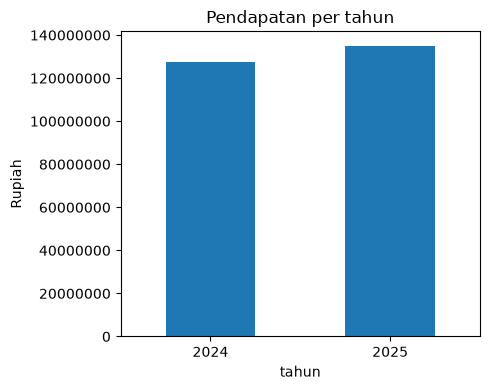

In [24]:
ax = hasil.plot(x="tahun", y="pendapatan_bersih", kind="bar",
                legend=False, rot=0, figsize=(5, 4))
ax.set_title("Pendapatan per tahun")
ax.set_ylabel("Rupiah")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.savefig("grafik_pendapatan_per_tahun.png", dpi=150)
plt.show()

## 11. Menyimpan Hasil

In [25]:
hasil.to_csv("hasil_pendapatan_per_tahun.csv", index=False)
print(pd.read_csv("hasil_pendapatan_per_tahun.csv"))

   tahun  jumlah_transaksi  pendapatan_kotor  pendapatan_bersih  total_diskon
0   2024              2327         130883500        127406475.0     3477025.0
1   2025              2345         138664000        135001100.0     3662900.0


## Kesimpulan

Data transaksi POS dibaca dan dibersihkan terlebih dahulu: missing value `kode_kasir` diisi, 30 baris duplikat dihapus, serta format tanggal dan harga diseragamkan. Pendapatan dihitung setelah diskon, hanya dari transaksi berstatus SELESAI dengan jumlah wajar (1-12).

| Tahun | Pendapatan Bersih |
|---|---|
| 2024 | Rp 127.406.475 |
| 2025 | Rp 135.001.100 |

Pendapatan naik sekitar 6% dari 2024 ke 2025. Tanpa penyaringan status dan jumlah, pendapatan 2025 terhitung sekitar Rp 271,9 juta, jauh dari angka sebenarnya. Jadi data mentah tidak boleh langsung dijumlahkan.

**Asumsi:** BATAL dan RETUR tidak dihitung, serta jumlah negatif atau lebih dari 12 dianggap salah input.